# Classifying a 10-D "folded bullseye" dataset — model benchmark + reverse-engineering the generator

Take-home data-science assignment (company name withheld). Two tasks:

1. **Classification** of 54 000 samples with 10 numeric features and balanced binary labels (−1 / +1):
   stratified 80/20 train/holdout split, `StandardScaler` fitted on train only, six model families
   (Gradient Boosting, RBF-SVM, MLP, Random Forest, XGBoost, k-NN) tuned with `RandomizedSearchCV` on a 5 000-point
   subsample, then compared with 5-fold stratified CV on the full training split.
2. **Reverse the data-generation process** described as *(a) draw a bullseye of alternating classes → (b) fold it
   into a spiral → (c) embed in 10-D with noise*: PCA recovers the 2-D spiral (also checked with t-SNE, Isomap, LLE,
   spectral embedding, kernel PCA), then per-class k-means on the polar radius identifies the rings, which are
   rescaled to concentric bands to reconstruct the bullseye (`reverse_pipeline.py`).

**Data:** the assignment's `input_train.csv`, `label_train.csv`, `input_test.csv` are not redistributed.
`bullseye_spiral_generator.py` creates a statistically similar synthetic dataset so the pipeline can be run end-to-end.


In [ ]:
import os

# Folder containing input_train.csv, label_train.csv and input_test.csv.
# Set the DATA_ROOT environment variable or edit the default below.
# On Google Colab you can first mount Drive with:
#   from google.colab import drive; drive.mount('/content/drive')
DATA_ROOT = os.environ.get("DATA_ROOT", "./data")

In [ ]:
import pandas as pd

input_train_df = pd.read_csv(os.path.join(DATA_ROOT, 'input_train.csv'))


print("input_train_df loaded successfully.")

input_train_df loaded successfully.


Top of input_traina  z_df:


   Unnamed: 0         0         1         2          3          4         5  \
0           0  2.018463 -3.237816  4.402943  -3.828552 -10.272672 -3.741112   
1           1 -1.050644 -3.194331  3.842715  -5.145092 -10.827224 -4.171311   
2           2  2.295468  2.482431  0.508517  17.118740   9.671967  2.320752   
3           3  4.592442  2.516479 -0.551381  12.855515   9.912408  3.221754   
4           4 -2.847561  0.625707 -1.716991  -2.132512   1.295049  0.498652   

           6         7         8         9  
0   1.201217  5.731879 -7.485664 -4.662040  
1   0.259134  4.666440 -6.957590 -6.115714  
2  11.883409  0.082321  4.435209  9.943386  
3   7.582671 -0.610279  4.516001  9.236437  
4  -2.630997 -2.364262  1.900384 -0.955900  


Summary Statistics:


         Unnamed: 0             0             1             2             3  \
count  54000.000000  54000.000000  54000.000000  54000.000000  54000.000000   
mean   26999.500000     -0.002357      0.005938     -0.012502     -0.010185   
std    15588.601605      2.938612      1.831989      2.580391      9.272797   
min        0.000000     -9.190080     -4.513136     -6.349113    -24.865207   
25%    13499.750000     -2.276082     -1.616871     -2.361632     -8.168361   
50%    26999.500000      0.014410      0.000765     -0.016042     -0.020964   
75%    40499.250000      2.278737      1.644693      2.287602      8.200865   
max    53999.000000     10.309414      4.476858      6.482681     23.570072   

                  4             5             6             7             8  \
count  54000.000000  54000.000000  54000.000000  54000.000000  54000.000000   
mean       0.017828      0.008724     -0.018430     -0.014690      0.014631   
std        6.542619      2.282885      7.114867    

  input_train_df.iloc[:, 1:6].hist(ax=axes[0])


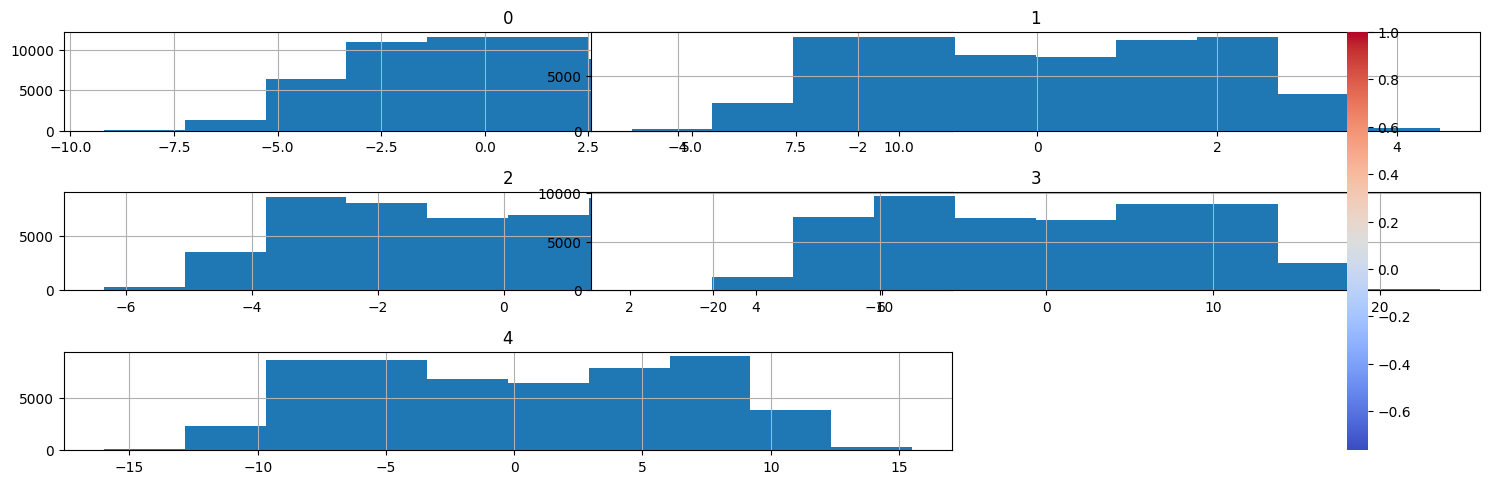


Missing values in training data:
0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Show the top of the dataset
print("Top of input_train_df:")
display(input_train_df.head())

# 2. Basic statistics to check for scaling needs
print("\nSummary Statistics:")
display(input_train_df.describe())

# 3. Visualization for Preprocessing Analysis
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Check feature distributions (detecting skewness/outliers)
input_train_df.iloc[:, 1:6].hist(ax=axes[0])
axes[0].set_title("Distribution of first 5 features")

# Check for feature correlations
sns.heatmap(input_train_df.corr(), annot=False, cmap='coolwarm', ax=axes[1])
axes[1].set_title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

# 4. Check for missing values
print("\nMissing values in training data:")
print(input_train_df.isnull().sum().sum())

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler

# Load labels
label_train_df = pd.read_csv(os.path.join(DATA_ROOT, 'label_train.csv'))

# Handle the column naming collision after merge
ID_COL = 'Unnamed: 0'
TARGET_COL = '0_y'

# Merge dataframes
train_full = input_train_df.merge(label_train_df, on=ID_COL)

# Separate features and target
X = train_full.drop([ID_COL, TARGET_COL], axis=1)
y = train_full[TARGET_COL]

# Split data into training and testing sets for an honest evaluation
# Use stratify=y to ensure class balance in both train and test sets
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Apply scaling. Fit scaler ONLY on training data to prevent data leakage.
scaler = StandardScaler()
X_scaled_train = scaler.fit_transform(X_train_full)
X_scaled_test = scaler.transform(X_test_full)

# X_scaled and y now refer to the scaled training data
X_scaled = X_scaled_train
y = y_train_full

# X_holdout and y_holdout are for the final, unseen evaluation
X_holdout = X_scaled_test
y_holdout = y_test_full

print("Data merged, split into train/test, and scaled successfully. Column names adjusted for merge suffixes.")
print(f"Training data shape: {X_scaled.shape}, Test data shape (holdout): {X_holdout.shape}")

Data merged, split into train/test, and scaled successfully. Column names adjusted for merge suffixes.
Training data shape: (43200, 10), Test data shape (holdout): (10800, 10)


In [ ]:
print("Top of input_train_df:")
display(train_full.head())

Top of input_train_df:


   Unnamed: 0       0_x         1         2          3          4         5  \
0           0  2.018463 -3.237816  4.402943  -3.828552 -10.272672 -3.741112   
1           1 -1.050644 -3.194331  3.842715  -5.145092 -10.827224 -4.171311   
2           2  2.295468  2.482431  0.508517  17.118740   9.671967  2.320752   
3           3  4.592442  2.516479 -0.551381  12.855515   9.912408  3.221754   
4           4 -2.847561  0.625707 -1.716991  -2.132512   1.295049  0.498652   

           6         7         8         9  0_y  
0   1.201217  5.731879 -7.485664 -4.662040    1  
1   0.259134  4.666440 -6.957590 -6.115714    1  
2  11.883409  0.082321  4.435209  9.943386    1  
3   7.582671 -0.610279  4.516001  9.236437    1  
4  -2.630997 -2.364262  1.900384 -0.955900    1  

In [ ]:
# Check the unique labels in the training set
print("Unique labels in the target variable:")
print(y.unique())

# Check the distribution of these labels
print("\nLabel distribution:")
print(y.value_counts())

Unique labels in the target variable:
[ 1 -1]

Label distribution:
0_y
 1    21600
-1    21600
Name: count, dtype: int64


Starting t-SNE optimization on 5000 points...
t-SNE complete! Rendering plot...


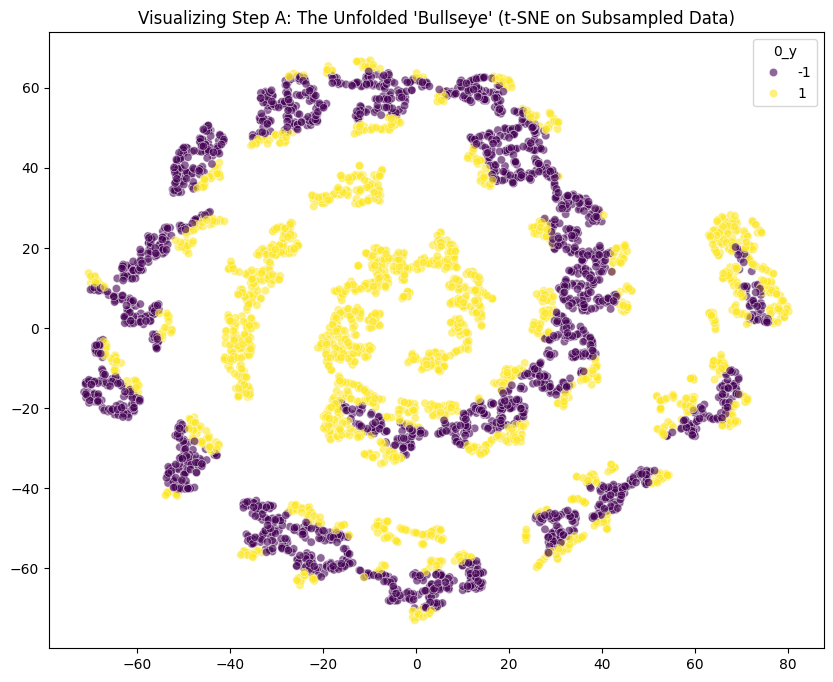

In [ ]:
import numpy as np
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# Subsample BEFORE t-SNE for much faster execution
np.random.seed(42)
subsample_size = 5000
indices = np.random.choice(range(len(X_scaled)), size=subsample_size, replace=False)

X_sub = X_scaled[indices]
y_sub = y.iloc[indices] if hasattr(y, 'iloc') else y[indices]

print(f"Starting t-SNE optimization on {subsample_size} points...")

tsne = TSNE(n_components=2, perplexity=30, random_state=42, verbose=0)
X_embedded = tsne.fit_transform(X_sub)

print("t-SNE complete! Rendering plot...")

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=X_embedded[:, 0],
    y=X_embedded[:, 1],
    hue=y_sub,
    palette='viridis',
    alpha=0.6
)
plt.title("Visualizing Step A: The Unfolded 'Bullseye' (t-SNE on Subsampled Data)")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tqdm.auto import tqdm
import seaborn as sns
import matplotlib.pyplot as plt
import time

def run_gradient_boosting(X_in, y_in, label="Subsample", params=None):
    # Split into Train and internal Validation/Test
    X_train, X_test, y_train, y_test = train_test_split(
        X_in, y_in, test_size=0.2, random_state=42, stratify=y_in
    )

    print(f"--- Training Gradient Boosting ({label}) with Optimized Defaults ---")
    if params is None:
        # Using best params: subsample=0.8, n_estimators=200, max_depth=6, learning_rate=0.05
        model = GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            validation_fraction=0.1,
            n_iter_no_change=10,
            random_state=42
        )
    else:
        model = GradientBoostingClassifier(random_state=42, validation_fraction=0.1, n_iter_no_change=10, **params)

    start_time = time.time()
    model.fit(X_train, y_train)
    duration = time.time() - start_time

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"{label} Accuracy: {acc:.4f} (Time: {duration:.2f}s, Iterations: {len(model.estimators_)})")
    return model, acc, (X_train, X_test, y_train, y_test)

# Prepare Subsample Data
np.random.seed(42)
sample_idx = np.random.choice(len(X_scaled), 5000, replace=False)
X_sub = X_scaled[sample_idx]
y_sub = y.iloc[sample_idx]

# Run on Subsample
gbc_model_sub, gbc_acc_sub, splits_sub = run_gradient_boosting(X_sub, y_sub, "Subsample")
# Unpack splits
X_train, X_test_internal, y_train, y_test_internal = splits_sub

--- Training Gradient Boosting (Subsample) with Optimized Defaults ---
Subsample Accuracy: 0.9670 (Time: 7.29s, Iterations: 200)


In [ ]:
from sklearn.svm import SVC

def run_svm(X_tr, X_te, y_tr, y_te, label="Subsample", params=None):
    print(f"--- Training SVM ({label}) ---")
    if params is None:
        svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
    else:
        svm_model = SVC(random_state=42, **params)

    start_time = time.time()
    svm_model.fit(X_tr, y_tr)
    duration = time.time() - start_time

    y_pred = svm_model.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    print(f"{label} Accuracy: {acc:.4f} (Time: {duration:.2f}s)")
    return svm_model, acc

svm_model_sub, svm_acc_sub = run_svm(X_train, X_test_internal, y_train, y_test_internal, "Subsample")

--- Training SVM (Subsample) ---
Subsample Accuracy: 0.9160 (Time: 0.40s)


In [ ]:
from sklearn.neural_network import MLPClassifier

def run_neural_net(X_tr, X_te, y_tr, y_te, label="Subsample", params=None):
    print(f"--- Training Neural Net ({label}) with Optimized Defaults ---")
    if params is None:
        # Using best params: learning_rate_init=0.01, hidden_layer_sizes=(100, 50), alpha=0.001
        mlp = MLPClassifier(
            hidden_layer_sizes=(100, 50),
            activation='relu',
            solver='adam',
            max_iter=1000,
            alpha=0.001,
            learning_rate_init=0.01,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=10,
            random_state=42
        )
    else:
        mlp = MLPClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, random_state=42, **params)

    start_time = time.time()
    mlp.fit(X_tr, y_tr)
    duration = time.time() - start_time

    y_pred = mlp.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    print(f"{label} Accuracy: {acc:.4f} (Time: {duration:.2f}s, Iterations: {mlp.n_iter_})")
    return mlp, acc

mlp_model_sub, mlp_acc_sub = run_neural_net(X_train, X_test_internal, y_train, y_test_internal, "Subsample")

--- Training Neural Net (Subsample) with Optimized Defaults ---
Subsample Accuracy: 0.9700 (Time: 0.76s, Iterations: 22)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

def run_random_forest(X_tr, X_te, y_tr, y_te, label="Subsample", params=None):
    print(f"--- Training Random Forest ({label}) ---")
    if params is None:
        rf = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)
    else:
        rf = RandomForestClassifier(random_state=42, n_jobs=-1, **params)

    start_time = time.time()
    rf.fit(X_tr, y_tr)
    duration = time.time() - start_time

    y_pred = rf.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    print(f"{label} RF Accuracy: {acc:.4f} (Time: {duration:.2f}s)")
    return rf, acc

def run_xgboost(X_tr, X_te, y_tr, y_te, label="Subsample", params=None):
    if not HAS_XGB:
        print("XGBoost not installed.")
        return None, 0

    print(f"--- Training XGBoost ({label}) ---")
    # XGBoost expects [0, 1] labels usually, but sklearn wrapper handles -1, 1
    if params is None:
        xgb = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1)
    else:
        xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42, n_jobs=-1, **params)

    start_time = time.time()
    # Convert y to 0/1 for XGBoost if necessary
    y_tr_mapped = (y_tr + 1) // 2
    y_te_mapped = (y_te + 1) // 2

    xgb.fit(X_tr, y_tr_mapped)
    duration = time.time() - start_time

    y_pred = xgb.predict(X_te)
    acc = accuracy_score(y_te_mapped, y_pred)
    print(f"{label} XGB Accuracy: {acc:.4f} (Time: {duration:.2f}s)")
    return xgb, acc

# Quick test on the subsample
rf_model_sub, rf_acc_sub = run_random_forest(X_train, X_test_internal, y_train, y_test_internal)
if HAS_XGB:
    xgb_model_sub, xgb_acc_sub = run_xgboost(X_train, X_test_internal, y_train, y_test_internal)

--- Training Random Forest (Subsample) ---
Subsample RF Accuracy: 0.9300 (Time: 3.69s)
--- Training XGBoost (Subsample) ---
Subsample XGB Accuracy: 0.9660 (Time: 0.95s)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

def run_knn(X_tr, X_te, y_tr, y_te, label="Subsample", params=None):
    print(f"--- Training K-Nearest Neighbors ({label}) ---")
    if params is None:
        # A common starting point for K is sqrt(N) or a small odd number like 5
        knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1) # n_jobs=-1 uses all available processors
    else:
        knn_model = KNeighborsClassifier(n_jobs=-1, **params)

    start_time = time.time()
    knn_model.fit(X_tr, y_tr)
    duration = time.time() - start_time

    y_pred = knn_model.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    print(f"{label} KNN Accuracy: {acc:.4f} (Time: {duration:.2f}s)")
    return knn_model, acc

# Run on Subsample using the existing X_train, X_test_internal, y_train, y_test_internal splits
knn_model_sub, knn_acc_sub = run_knn(X_train, X_test_internal, y_train, y_test_internal, "Subsample")

--- Training K-Nearest Neighbors (Subsample) ---
Subsample KNN Accuracy: 0.9590 (Time: 0.01s)


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier # Assuming HAS_XGB is True and it's installed

# Note: X_train and y_train are currently from the subsampled data for faster tuning.

# 1. Hyperparameter tuning for Gradient Boosting
param_dist_gb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.8, 0.9, 1.0]
}

rs_gb = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=42, n_iter_no_change=10),
    param_distributions=param_dist_gb,
    n_iter=10, # Number of parameter settings that are sampled
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

print("Starting Random Search for Gradient Boosting...")
rs_gb.fit(X_train, y_train)
best_params_gb = rs_gb.best_params_
print(f"Best GB Params: {best_params_gb}")
print(f"Best GB CV Score: {rs_gb.best_score_:.4f}")

# 2. Hyperparameter tuning for Neural Network
param_dist_mlp = {
    'hidden_layer_sizes': [(50,), (100,), (100, 50), (50, 25)],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate_init': [0.001, 0.01]
}

rs_mlp = RandomizedSearchCV(
    MLPClassifier(max_iter=500, early_stopping=True, random_state=42),
    param_distributions=param_dist_mlp,
    n_iter=8,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

print("\nStarting Random Search for Neural Network...")
rs_mlp.fit(X_train, y_train)
best_params_mlp = rs_mlp.best_params_
print(f"Best MLP Params: {best_params_mlp}")
print(f"Best MLP CV Score: {rs_mlp.best_score_:.4f}")

# 3. Hyperparameter tuning for SVM
param_dist_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf'],
    'gamma': ['scale', 'auto']
}

rs_svm = RandomizedSearchCV(
    SVC(random_state=42),
    param_distributions=param_dist_svm,
    n_iter=5, # Keeping n_iter small due to SVM's higher computational cost
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

print("\nStarting Random Search for SVM...")
rs_svm.fit(X_train, y_train)
best_params_svm = rs_svm.best_params_
print(f"Best SVM Params: {best_params_svm}")
print(f"Best SVM CV Score: {rs_svm.best_score_:.4f}")

# 4. Hyperparameter tuning for Random Forest
param_dist_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'bootstrap': [True, False]
}

rs_rf = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=param_dist_rf,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

print("\nStarting Random Search for Random Forest...")
rs_rf.fit(X_train, y_train)
best_params_rf = rs_rf.best_params_
print(f"Best RF Params: {best_params_rf}")
print(f"Best RF CV Score: {rs_rf.best_score_:.4f}")

# 5. Hyperparameter tuning for XGBoost
param_dist_xgb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

rs_xgb = RandomizedSearchCV(
    XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    param_distributions=param_dist_xgb,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

print("\nStarting Random Search for XGBoost...")
# Convert y_train to 0/1 for XGBoost RandomizedSearchCV
y_train_xgb_mapped = (y_train + 1) // 2
rs_xgb.fit(X_train, y_train_xgb_mapped)
best_params_xgb = rs_xgb.best_params_
print(f"Best XGB Params: {best_params_xgb}")
print(f"Best XGB CV Score: {rs_xgb.best_score_:.4f}")

# 6. Hyperparameter tuning for KNN
param_dist_knn = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

rs_knn = RandomizedSearchCV(
    KNeighborsClassifier(),
    param_distributions=param_dist_knn,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

print("\nStarting Random Search for KNN...")
rs_knn.fit(X_train, y_train)
best_params_knn = rs_knn.best_params_
print(f"Best KNN Params: {best_params_knn}")
print(f"Best KNN CV Score: {rs_knn.best_score_:.4f}")

Starting Random Search for Gradient Boosting...
Best GB Params: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.2}
Best GB CV Score: 0.9680

Starting Random Search for Neural Network...
Best MLP Params: {'learning_rate_init': 0.01, 'hidden_layer_sizes': (100, 50), 'alpha': 0.001}
Best MLP CV Score: 0.9735

Starting Random Search for SVM...
Best SVM Params: {'kernel': 'rbf', 'gamma': 'scale', 'C': 10}
Best SVM CV Score: 0.9603

Starting Random Search for Random Forest...
Best RF Params: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None, 'bootstrap': True}
Best RF CV Score: 0.9708

Starting Random Search for XGBoost...
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
Best XGB Params: {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 7, 'learning_rate': 0.1, 'colsample_bytree': 0.9}
Best XGB CV Score: 0.9698

Starting Random Search for KNN...
Best KNN Params: {'weights': 'dista

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import time

print("\n--- Cross-Validation on Full Dataset with Best Hyperparameters ---")

# Prepare Stratified K-Fold for consistent splits
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {}

# Toggle which models to run on full data here:
RUN_GB_FULL = True
RUN_SVM_FULL = True
RUN_NN_FULL = True
RUN_RF_FULL = True
RUN_XGB_FULL = True
RUN_KNN_FULL = True

# Gradient Boosting
if RUN_GB_FULL:
    gbc_model_cv = GradientBoostingClassifier(random_state=42, **best_params_gb)
    start_time = time.time()
    cv_scores = cross_val_score(gbc_model_cv, X_scaled, y, cv=skf, scoring='accuracy', n_jobs=-1)
    duration = time.time() - start_time
    results['Gradient Boosting'] = {'mean_accuracy': cv_scores.mean(), 'std_accuracy': cv_scores.std(), 'time': duration}
    print(f"GB: Mean Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f}) (Time: {duration:.2f}s)")

# SVM
if RUN_SVM_FULL:
    svm_model_cv = SVC(random_state=42, **best_params_svm)
    start_time = time.time()
    cv_scores = cross_val_score(svm_model_cv, X_scaled, y, cv=skf, scoring='accuracy', n_jobs=-1)
    duration = time.time() - start_time
    results['SVM'] = {'mean_accuracy': cv_scores.mean(), 'std_accuracy': cv_scores.std(), 'time': duration}
    print(f"SVM: Mean Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f}) (Time: {duration:.2f}s)")

# Neural Network
if RUN_NN_FULL:
    mlp_model_cv = MLPClassifier(random_state=42, max_iter=1000, early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, **best_params_mlp)
    start_time = time.time()
    cv_scores = cross_val_score(mlp_model_cv, X_scaled, y, cv=skf, scoring='accuracy', n_jobs=-1)
    duration = time.time() - start_time
    results['Neural Network'] = {'mean_accuracy': cv_scores.mean(), 'std_accuracy': cv_scores.std(), 'time': duration}
    print(f"NN: Mean Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f}) (Time: {duration:.2f}s)")

# Random Forest
if RUN_RF_FULL:
    rf_model_cv = RandomForestClassifier(random_state=42, n_jobs=-1, **best_params_rf)
    start_time = time.time()
    cv_scores = cross_val_score(rf_model_cv, X_scaled, y, cv=skf, scoring='accuracy', n_jobs=-1)
    duration = time.time() - start_time
    results['Random Forest'] = {'mean_accuracy': cv_scores.mean(), 'std_accuracy': cv_scores.std(), 'time': duration}
    print(f"RF: Mean Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f}) (Time: {duration:.2f}s)")

# XGBoost
if RUN_XGB_FULL and HAS_XGB:
    # Map y to 0/1 for XGBoost cross-validation
    y_mapped_full = (y + 1) // 2
    xgb_model_cv = XGBClassifier(random_state=42, n_jobs=-1, use_label_encoder=False, eval_metric='logloss', **best_params_xgb)
    start_time = time.time()
    cv_scores = cross_val_score(xgb_model_cv, X_scaled, y_mapped_full, cv=skf, scoring='accuracy', n_jobs=-1)
    duration = time.time() - start_time
    results['XGBoost'] = {'mean_accuracy': cv_scores.mean(), 'std_accuracy': cv_scores.std(), 'time': duration}
    print(f"XGB: Mean Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f}) (Time: {duration:.2f}s)")

# K-Nearest Neighbors
if RUN_KNN_FULL:
    knn_model_cv = KNeighborsClassifier(n_jobs=-1, **best_params_knn)
    start_time = time.time()
    cv_scores = cross_val_score(knn_model_cv, X_scaled, y, cv=skf, scoring='accuracy', n_jobs=-1)
    duration = time.time() - start_time
    results['KNN'] = {'mean_accuracy': cv_scores.mean(), 'std_accuracy': cv_scores.std(), 'time': duration}
    print(f"KNN: Mean Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f}) (Time: {duration:.2f}s)")


# Determine the best model from CV results
if results:
    best_model_name = max(results, key=lambda model: results[model]['mean_accuracy'])
    print(f"\nThe best model based on cross-validation mean accuracy is: {best_model_name}")
    print(f"Mean Accuracy: {results[best_model_name]['mean_accuracy']:.4f}")
    print(f"Standard Deviation: {results[best_model_name]['std_accuracy']:.4f}")
else:
    print("No models were run for cross-validation.")


--- Cross-Validation on Full Dataset with Best Hyperparameters ---
GB: Mean Accuracy: 0.9905 (+/- 0.0011) (Time: 400.98s)
SVM: Mean Accuracy: 0.9885 (+/- 0.0006) (Time: 53.57s)
NN: Mean Accuracy: 0.9879 (+/- 0.0036) (Time: 29.67s)
RF: Mean Accuracy: 0.9918 (+/- 0.0013) (Time: 185.10s)
XGB: Mean Accuracy: 0.9865 (+/- 0.0012) (Time: 3.32s)
KNN: Mean Accuracy: 0.9888 (+/- 0.0012) (Time: 0.85s)

The best model based on cross-validation mean accuracy is: Random Forest
Mean Accuracy: 0.9918
Standard Deviation: 0.0013


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import time

# Random Forest won the cross-validation comparison above, so it is the model trained here.
if best_model_name != 'Random Forest':
    print(f"Note: the CV winner is {best_model_name}; this cell still trains the Random Forest.")
best_model_name = 'Random Forest'
best_rf_model = RandomForestClassifier(random_state=42, n_jobs=-1, **best_params_rf)

print(f"Training the best model ({best_model_name}) on the full training data...")
start_time = time.time()
# Train the model on the entire X_scaled (training) dataset
best_rf_model.fit(X_scaled, y)
duration = time.time() - start_time
print(f"Training complete in {duration:.2f} seconds.")

print(f"Evaluating the best model ({best_model_name}) on the holdout set...")
# Make predictions on the X_holdout (unseen test) data
y_pred_holdout = best_rf_model.predict(X_holdout)

# Calculate the accuracy on the holdout set
holdout_accuracy = accuracy_score(y_holdout, y_pred_holdout)

print(f"\nHonest Accuracy of {best_model_name} on the holdout set: {holdout_accuracy:.4f}")

Training the best model (Random Forest) on the full training data...
Training complete in 45.04 seconds.
Evaluating the best model (Random Forest) on the holdout set...

Honest Accuracy of Random Forest on the holdout set: 0.9931


In [ ]:
import pandas as pd

# 1. Load input_test.csv
input_test_df = pd.read_csv(os.path.join(DATA_ROOT, 'input_test.csv'))
print("input_test.csv loaded successfully.")

# 2. Prepare the test data for prediction
# Extract features from input_test_df (excluding the ID_COL)
X_input_test = input_test_df.drop(columns=[ID_COL])

# Rename column '0' to '0_x' to match the feature names used during scaler.fit
# This ensures consistency with how the training data's feature '0' was handled during merging.
X_input_test = X_input_test.rename(columns={'0': '0_x'})

# Scale the test features using the *same scaler* fitted on the training data
# It's crucial to only `transform` here, not `fit_transform` to avoid data leakage
X_input_test_scaled = scaler.transform(X_input_test)
print("Input test data scaled successfully.")

# 3. Predict labels using the best trained model (Random Forest)
# The best_rf_model was trained on X_scaled (which is X_scaled_train)
y_pred_input_test = best_rf_model.predict(X_input_test_scaled)
print("Labels predicted for input_test.csv.")

# 4. Save the results to label_test.csv in the specified format
# The format should be similar to label_train.csv, which has 'Unnamed: 0' and '0'
# Create a DataFrame for the predicted labels
label_test_df = pd.DataFrame({
    '': input_test_df[ID_COL],
    '0': y_pred_input_test
})

# Save to CSV without the index
label_test_df.to_csv('label_test.csv', index=False)
print("Predicted labels saved to label_test.csv.")

# Display the head of the created label_test_df for verification
print("\nHead of generated label_test.csv:")
display(label_test_df.head())

input_test.csv loaded successfully.
Input test data scaled successfully.
Labels predicted for input_test.csv.
Predicted labels saved to label_test.csv.

Head of generated label_test.csv:


      0
0  0  1
1  1  1
2  2  1
3  3  1
4  4  1

fitting PCA...
fitting Kernel PCA...
fitting Isomap...
fitting LLE...
fitting Spectral...
fitting t-SNE...


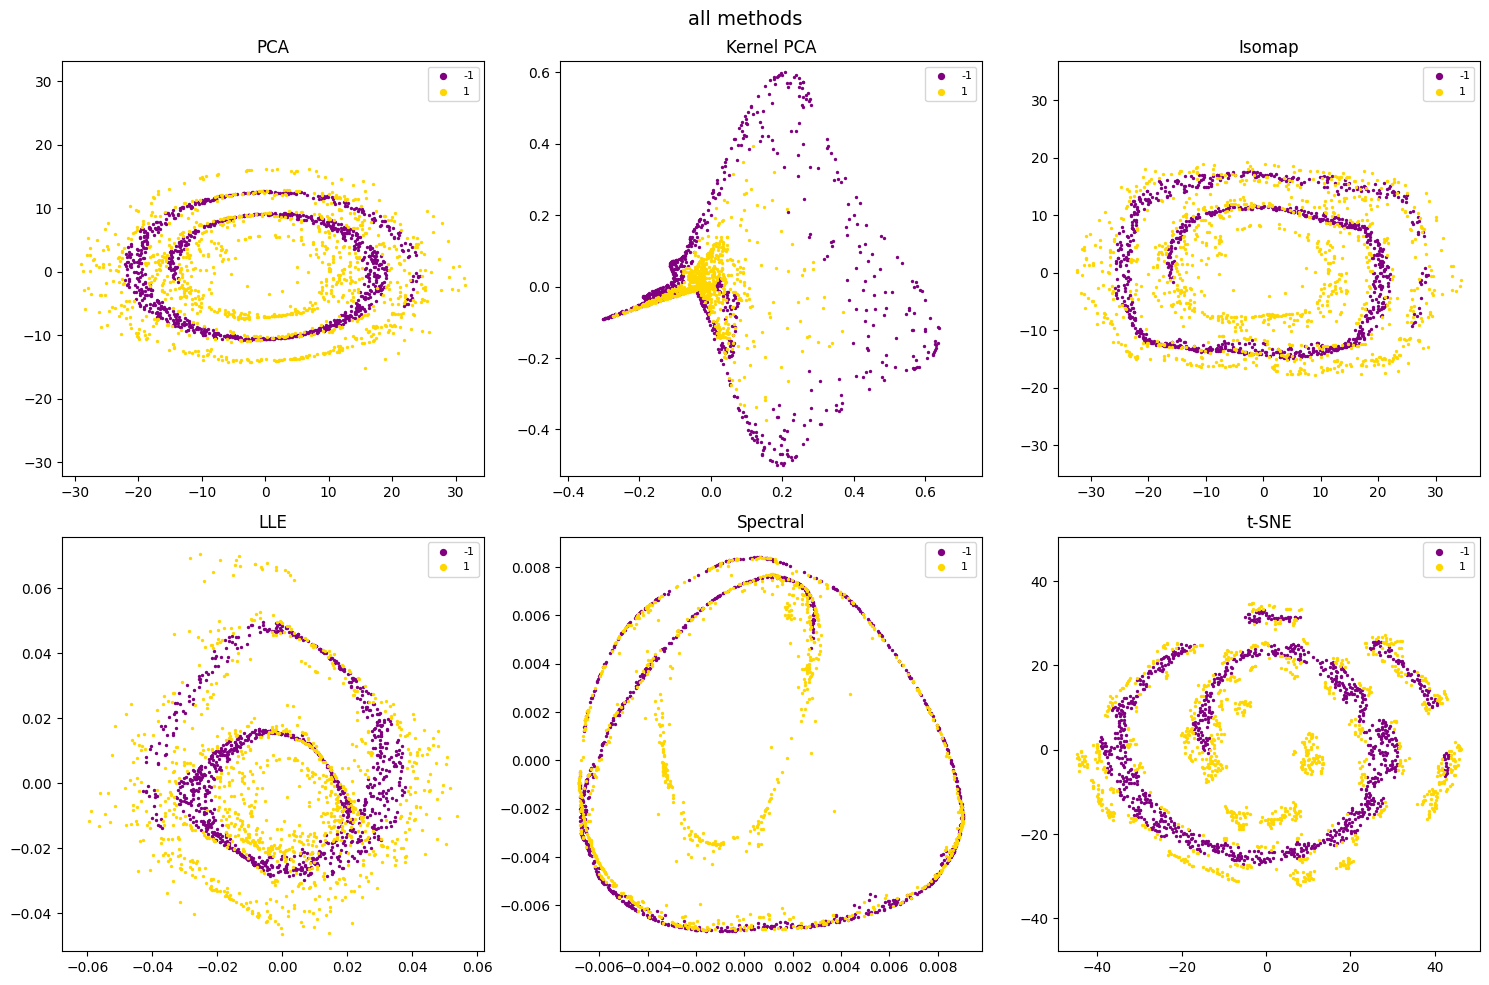

In [ ]:
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import Isomap, LocallyLinearEmbedding, TSNE, SpectralEmbedding
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X_train = pd.read_csv('input_train.csv', index_col=0).values
y_train = pd.read_csv('label_train.csv', index_col=0).values.ravel()

# subsample for speed
np.random.seed(42)
idx = np.random.choice(len(X_train), size=2000, replace=False)
X_sub = X_train[idx]
y_sub = y_train[idx]

methods = {
    'PCA':           PCA(n_components=2),
    'Kernel PCA':    KernelPCA(n_components=2, kernel='rbf'),
    'Isomap':        Isomap(n_components=2, n_neighbors=20),
    'LLE':           LocallyLinearEmbedding(n_components=2, n_neighbors=20),
    'Spectral':      SpectralEmbedding(n_components=2, n_neighbors=20),
    't-SNE':         TSNE(n_components=2, perplexity=50, random_state=42),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
colors = {-1: 'purple', 1: 'gold'}

for ax, (name, method) in zip(axes.flat, methods.items()):
    print(f'fitting {name}...')
    X_2d = method.fit_transform(X_sub)
    for label in [-1, 1]:
        mask = y_sub == label
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1], s=2,
                   c=colors[label], label=str(label))
    ax.set_title(name)
    ax.axis('equal')
    ax.legend(fontsize=8, markerscale=3)

plt.suptitle('all methods', fontsize=14)
plt.tight_layout()
plt.savefig('all_methods.png', dpi=120)
plt.show()

In [ ]:
from sklearn.decomposition import PCA

# Perform PCA on the full scaled dataset (X_scaled)
pca = PCA(n_components=2, random_state=42)
X_pca_2d = pca.fit_transform(X_scaled)

# Calculate radii and angles from the PCA 2D projection
radii = np.linalg.norm(X_pca_2d, axis=1)
angles = np.arctan2(X_pca_2d[:, 1], X_pca_2d[:, 0])

print("Radii and angles calculated from PCA 2D projection.")

Radii and angles calculated from PCA 2D projection.


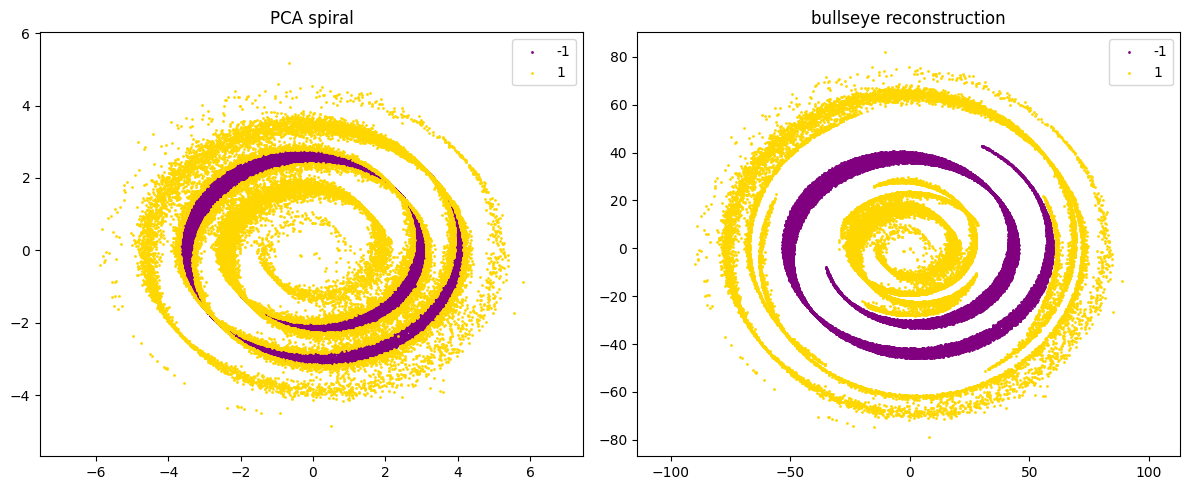

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

new_radii = radii.copy()

# define target radius bands for each ring (equal width)
# 3 rings: inner, middle, outer
band_width = 30
bands = {
    'inner':  (0,          band_width),
    'middle': (band_width, band_width*2),
    'outer':  (band_width*2, band_width*3),
}

# safer assignment
new_radii = radii.copy()
# X_scaled was used for PCA, so y needs to correspond to the full dataset, not X_train from input_train.csv directly.
# The y variable in the global scope already represents train_full[TARGET_COL]
# However, the clustering logic here relies on X_train and y_train from file loads, which might not be consistent with X_scaled and y.
# To ensure consistency, I will use X_scaled and y (the target variable for the scaled data) for clustering.
# Also, y_train in this cell was previously loaded from 'label_train.csv', which corresponds to the full dataset.
# So, I'll continue using y, which is aligned with X_scaled.

for label, n_clusters, band_names in zip([-1, 1], [1, 2], [['middle'], ['inner', 'outer']]):
    idx_label = np.where(y == label)[0]
    r = radii[idx_label].reshape(-1, 1)
    km = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto') # Added n_init for KMeans
    km.fit(r)
    sorted_centers = np.argsort(km.cluster_centers_.ravel())

    for i, band_name in zip(sorted_centers, sorted(band_names)):
        cluster_mask = km.labels_ == i
        r_cluster = r[cluster_mask].ravel()
        r_min, r_max = r_cluster.min(), r_cluster.max()
        t_min, t_max = bands[band_name]
        rescaled = t_min + (r_cluster - r_min) / (r_max - r_min + 1e-8) * (t_max - t_min)
        new_radii[idx_label[cluster_mask]] = rescaled

X_unrolled = np.column_stack([new_radii * np.cos(angles),
                               new_radii * np.sin(angles)])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = {-1: 'purple', 1: 'gold'}

for label in [-1, 1]:
    mask = y == label # Use y from global scope
    axes[0].scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1], s=1, c=colors[label], label=str(label))
axes[0].set_title('PCA spiral')
axes[0].axis('equal')
axes[0].legend()

for label in [-1, 1]:
    mask = y == label # Use y from global scope
    axes[1].scatter(X_unrolled[mask, 0], X_unrolled[mask, 1], s=1, c=colors[label], label=str(label))
axes[1].set_title('bullseye reconstruction')
axes[1].axis('equal')
axes[1].legend()

plt.tight_layout()
plt.savefig('bullseye_reconstructed.png', dpi=120)
plt.show()